(lineage_recorders)=

# Lineage recorders

A lineage barcode marks the cells of a clone, the descendants of one labelled cell, but cannot tell how the cells within the clone are related. A lineage recorder keeps writing heritable edits into target sites in the genome as cells divide, so the edits that two cells share record their common ancestors, and from the edits of all cells a tool can reconstruct a phylogeny: a tree whose leaves are the sampled cells and whose internal nodes are their ancestors. Cutting the tree at a time groups the cells into clones, each holding the descendants of one lineage alive at that time, and the cell types that share these clones show which fates were still open to a common ancestor then.

This page follows one mouse embryo that @Colgan_2026 traced with PEtracer and collected at embryonic day 7.5 (E7.5), during gastrulation. PEtracer [@Koblan_2025] records with a prime editor: the authors' mouse embryonic stem cells carry 35 copies of a target cassette in their genome, each copy with its own barcode and three sites, and the editor writes one of eight five-base insertions, the lineage marks, into each site as the cells divide. The embryo is a chimera: four to eight stem cells carrying PEtracer were injected into a host embryo at the 8-cell stage, and their descendants, the donor cells, make up most of the embryo. The page builds an expression store, labels the cells with the authors' cell types, reads the marks of each cell, imports the trees that the authors reconstructed, cuts them at five times from E5.0 to E7.0, and asks at each cut which cell types share more clones than chance.

## Download the embryo

GEO series [GSE342226](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE342226) holds embryo E7.5-R1 in two samples: GSM9925879, the expression matrix that Cell Ranger counted, and GSM9925880, the character matrix, which lists the marks of each cell, with the two trees that the authors reconstructed from it. The authors also released the data under the MIT License as the Mouse Embryonic Lineage Atlas on [Zenodo](https://zenodo.org/records/23088914), with a table of their annotation of the donor cells of all 16 embryos. The table takes 359 MB and lists the 1,032 donor cells of E7.5-R1 first, so download only its first 185,933 bytes, the header and those rows, with an HTTP range request. The downloads take 34 MB together.

The example uses a temporary directory. Use a project directory instead if you want to keep the downloaded files and the store after closing the notebook.

In [1]:
# Download and verify the published files.
import hashlib
import shutil
from pathlib import Path
from tempfile import TemporaryDirectory
from urllib.request import Request, urlopen

# Summarize the results in tables.
import pandas as pd

# Analyze the embryo.
import cytearc

# Keep routine logs and progress bars out of the results.
cytearc.configure_output(level="WARNING", progress=False)

# Keep this example's downloads and store together.
work = TemporaryDirectory()
output_dir = Path(work.name)

Started: 2026-11-06T09:04:57.795526Z | Wall time: 0.448 s

In [2]:
# Pin each file so that a changed download cannot alter the example silently,
# and name the files as the authors name the embryo and its clones.
geo = "https://ftp.ncbi.nlm.nih.gov/geo/samples/GSM9925nnn"
sources = {
    "E7.5-R1_matrix.mtx.gz": (
        f"{geo}/GSM9925879/suppl/GSM9925879_E7.5-R1_matrix.mtx.gz",
        "d246178e0c6e045b735ac36770ecdbe73cbbdc1628b2b48945f7050e959d33a8",
    ),
    "E7.5-R1_features.tsv.gz": (
        f"{geo}/GSM9925879/suppl/GSM9925879_E7.5-R1_features.tsv.gz",
        "28ab91827cb07d8ba9071ebe98101ade7a0f7a3f8f7d48b28c8e1f807f062c70",
    ),
    "E7.5-R1_barcodes.tsv.gz": (
        f"{geo}/GSM9925879/suppl/GSM9925879_E7.5-R1_barcodes.tsv.gz",
        "47d445ff2cf5944ab66dfda8f0db3d5e91690d29c086de0a7c0a957b3309de66",
    ),
    "E7.5-R1_characters.csv.gz": (
        f"{geo}/GSM9925880/suppl/GSM9925880_E7.5-R1_characters.csv.gz",
        "166131c571ca30338435d25bd3f437512e44c79a5d428953fe72d04bb4385e85",
    ),
    "E7.5-R1-C1.nwk.gz": (
        f"{geo}/GSM9925880/suppl/GSM9925880_E7.5-R1_E7.5-R1-C1.nwk.gz",
        "85e822845ca9774c9ca060375ea177f4b96a8b3994d00d297b1de15f6746714d",
    ),
    "E7.5-R1-C2.nwk.gz": (
        f"{geo}/GSM9925880/suppl/GSM9925880_E7.5-R1_E7.5-R1-C2.nwk.gz",
        "37f008640400fcee2b15d2988ce64c856d1d0e017229fff71d86a125773b562d",
    ),
    "E7.5-R1_cells.csv": (
        "https://zenodo.org/records/23088914/files/E7.5-E10_cells.csv",
        "f96960f5f78f2d15321ef6acf3eecb546a0dc1f3a8aa074472212a3c13a4e341",
    ),
}

# Read only the header and the rows of E7.5-R1 from the atlas's cell table.
byte_ranges = {"E7.5-R1_cells.csv": "bytes=0-185932"}

paths = {}
for name, (url, expected_digest) in sources.items():
    path = output_dir / name

    # Copy the response in blocks without holding the file in memory, and
    # refuse a whole table sent in place of the bytes requested.
    headers = {"Range": byte_ranges[name]} if name in byte_ranges else {}
    with urlopen(Request(url, headers=headers), timeout=60) as response:
        if headers and response.status != 206:
            raise ValueError(f"{url} was sent whole, not the bytes requested")
        with path.open("wb") as target:
            shutil.copyfileobj(response, target)

    # Reject a file whose contents differ from the verified source.
    with path.open("rb") as source:
        actual_digest = hashlib.file_digest(source, "sha256").hexdigest()
    if actual_digest != expected_digest:
        raise ValueError(f"Checksum mismatch for {path.name}")
    paths[name] = path

# Show the size of each completed download.
pd.Series(
    {name: path.stat().st_size / 1_000_000 for name, path in paths.items()},
    name="Downloaded MB",
).round(2)

E7.5-R1_matrix.mtx.gz        33.50
E7.5-R1_features.tsv.gz       0.64
E7.5-R1_barcodes.tsv.gz       0.01
E7.5-R1_characters.csv.gz     0.03
E7.5-R1-C1.nwk.gz             0.02
E7.5-R1-C2.nwk.gz             0.00
E7.5-R1_cells.csv             0.19
Name: Downloaded MB, dtype: float64

Started: 2026-11-06T09:04:58.245886Z | Wall time: 8.999 s

## Build the expression store

The expression matrix counts 78,258 genes of the GENCODE vM37 annotation in the 1,342 cells that the authors kept after quality control, host cells among them. `inspect_mtx` pairs the matrix with its gene and cell files, and `MtxToZarr` writes them into a new store.

In [3]:
# Pair the matrix with its gene and cell files, and write them into a new store.
(candidate,) = cytearc.inspect_mtx(str(paths["E7.5-R1_matrix.mtx.gz"]))
store_path = output_dir / "E7.5-R1.zarr"
cytearc.MtxToZarr(cytearc.MtxReader(candidate), zarr_loc=str(store_path)).dump()

# Open the store, with its RNA assay as the default.
ds = cytearc.DataStore(str(store_path), default_assay="RNA")
ds

DataStore has 1342 (1342) cells with 1 assays: RNA
   Cell metadata:
            'I', 'ids', 'names', 'RNA_nCounts', 'RNA_nFeatures', 
            'RNA_percentMito', 'RNA_percentRibo'
   RNA assay has 78258 features and following metadata:
            'I', 'ids', 'names', 'dropOuts', 'feature_type', 
            'nCells'

Started: 2026-11-06T09:05:07.246777Z | Wall time: 9.687 s

The authors annotated 99 cell types over the 16 embryos, and their table gives each donor cell its type. The table lists the 1,032 donor cells of E7.5-R1 and none of the host embryo's cells, so label the other 310 cells `host`. Save the labels as a cell column, so that later steps can group cells by type.

In [4]:
# Read the authors' annotation, and check that it names this embryo's cells.
annotation = pd.read_csv(paths["E7.5-R1_cells.csv"], index_col=0)
cell_ids = pd.Index(ds.cells.fetch_all("ids"))
if not (
    annotation["embryo"].eq("E7.5-R1").all() and annotation.index.isin(cell_ids).all()
):
    raise ValueError("The annotation names cells outside this embryo's store")

# Label each cell with its type, and the cells that the table leaves out as host.
cell_types = annotation["cell_type"].reindex(cell_ids, fill_value="host")
ds.cells.insert("cell_type", cell_types, overwrite=True)

# Count the cells of each type.
cell_types.value_counts().rename("Cells").rename_axis("Cell type").to_frame()

,Cells
Cell type,
Nascent mesoderm,325
host,310
Rostral ectoderm,215
Epiblast,175
Extraembryonic mesoderm,134
Primitive streak,91
Definitive endoderm,39
Hematoendothelial progenitor,32
Notochord,17


Started: 2026-11-06T09:05:16.935931Z | Wall time: 0.032 s

Place the cell types on a map of expression. The RNA recipe selects variable genes, normalizes the counts, reduces them with PCA, embeds the cells with UMAP and clusters them. The authors' quality control already kept these cells, so `filtering=False` analyzes all of them.

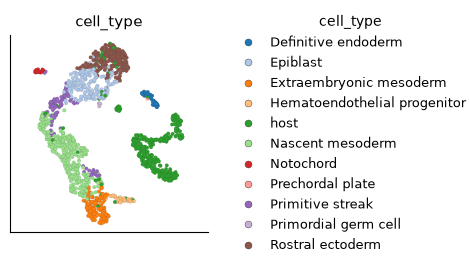

Started: 2026-11-06T09:05:16.970454Z | Wall time: 92.011 s

In [5]:
# Embed every cell with the RNA recipe, keeping the cells that the authors kept.
run = ds.pipeline.rna(label="rna", filtering=False)

# Locate the cell types on the UMAP.
ds.plots.embedding(layout=run["umap"], color_by="cell_type")

The epiblast, the layer whose cells give every germ layer of the embryo, sits between the rostral ectoderm and the primitive streak, where epiblast cells ingress to form mesoderm and endoderm. From the streak, the nascent mesoderm runs to the extraembryonic mesoderm and the hematoendothelial progenitors, which give the first blood and vessels. The definitive endoderm and the notochord form small groups apart. The host's cells, which the table leaves out, gather mostly in a group of their own, apart from every donor cell type; the authors found that donor cells contribute little to the extraembryonic endoderm and ectoderm [@Colgan_2026].

## Read the character matrix

PEtracer's character matrix holds one row per cell and one column per site, named by its integration and site, such as `intID250-EMX1`: an integration is one cassette in the genome, named by the ID of its barcode, and its sites are EMX1, HEK3 and RNF2. An entry is `*` for an unedited site, `1` to `8` for one of the lineage marks, `!` for another insertion and `-` for a site that was not read. `clones.import_alleles` recognizes the format, joins each row to the cell of the same ID and saves the marks as a `lineage_alleles` artifact.

In [6]:
# Read the marks of every cell.
cells = ds.snapshot_cell_selection("I")
alleles = ds.clones.import_alleles(
    paths["E7.5-R1_characters.csv.gz"], cell_selection=cells
)

# Compare the donor and host cells by the integrations read and the sites edited.
allele_cells = ds.clones.load_alleles(alleles).cells[["n_integrations", "n_edits"]]
origin = cell_types.eq("host").map({True: "Host", False: "Donor"}).rename("Origin")
allele_cells.groupby(origin).agg(["min", "median", "max"])

n_integrations            n_edits           
                  min median max     min median max
Origin                                             
Donor              29   33.0  33      34   47.0  64
Host                0    0.0   0       0    0.0   0

Started: 2026-11-06T09:06:48.983430Z | Wall time: 0.354 s

Each donor cell reads 29 to 33 of the matrix's 33 integrations, and holds a mark at 34 to 64 of its 99 sites. The host's cells read none, since the host embryo carries no recorder: every one of their sites holds `-`. GEO's description of the matrix calls `*` missing, but these cells show that `-` is, as the Zenodo record says. Draw each site's share of the cells in each state, and compare the three kinds of site by how many of the cells that read them hold a mark.

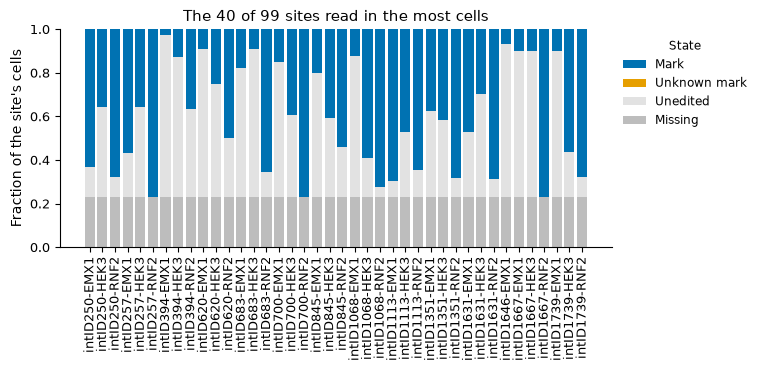

Started: 2026-11-06T09:06:49.339124Z | Wall time: 0.615 s

In [7]:
# Draw each site's share of the cells in each state.
ds.plots.recorder_states(alleles)

In [8]:
# Compare the three sites by the share of the cells reading them that hold a mark.
states = (
    ds.clones.load_alleles(alleles)
    .site_states()
    .pivot_table(
        index=["integration", "site"], columns="state", values="n_cells", observed=True
    )
)
edited = states["mark"] + states["unknown_mark"]
(edited / (edited + states["unedited"])).groupby(level="site").describe()[
    ["min", "50%", "max"]
].round(2)

,min,50%,max
site,,,
EMX1,0.00,0.23,0.91
HEK3,0.00,0.43,1.00
RNF2,0.04,0.84,1.00


Started: 2026-11-06T09:06:49.956347Z | Wall time: 0.091 s

The missing part of every bar, 23% of the cells, is the host's cells, since most donor cells read every integration. The three kinds of site fill at different rates: by E7.5 the median RNF2 site holds a mark in 84% of the cells that read it, the median HEK3 site in 43% and the median EMX1 site in 23%, and within each kind the sites range from under 5% of the cells to over 90%. A site that fills fast records early divisions and then stops changing, while a slow site keeps unedited copies for later divisions, so sites of different rates record different periods.

## Export the characters for tree builders

CyteArc reads trees but does not build them. Tools such as Cassiopeia [@Jones_2020] and LAML [@Mai_2024] build trees from a character matrix, which `clones.export_characters` writes: by default a TreeData store that Cassiopeia's solvers read, or with `format="laml"` the CSV that LAML reads. Cells that read no site are left out.

In [9]:
# Write the marks as a character matrix for Cassiopeia's solvers.
exported = ds.clones.export_characters(alleles, output_dir / "E7.5-R1_characters.zarr")
exported.diagnostics

{'cells': 1032, 'characters': 99, 'cellsWithSeveralAlleleRows': 0}

Started: 2026-11-06T09:06:50.050004Z | Wall time: 0.700 s

## Import the clone trees

The authors built one tree per embryo and split it at its root into one tree per founder clone, the descendants of one injected stem cell; E7.5-R1 holds two. The authors estimated each branch's length from the marks gained along it and scaled the lengths so that every tree runs from day 0 at its root to day 7.5 at its leaves, so a node's time estimates the embryonic day on which that ancestor divided. `clones.import_phylogeny` reads the two Newick files and joins each leaf to the cell that it names. The files do not state their unit, so `time_unit="days"` declares it.

In [10]:
# Import the two clone trees, whose lengths are days.
phylogeny = ds.clones.import_phylogeny(
    [paths["E7.5-R1-C1.nwk.gz"], paths["E7.5-R1-C2.nwk.gz"]],
    cell_selection=cells,
    time_unit="days",
)

# Count the cells that no leaf names, and describe each tree.
diagnostics = ds.artifacts.inspect(phylogeny).diagnostics
print(diagnostics["cellsInNoTree"], "cells are in no tree")
ds.clones.load_phylogeny(phylogeny).trees

310 cells are in no tree


,tree,n_nodes,n_leaves,n_cells,root_time,earliest_leaf_time,latest_leaf_time
0,E7.5-R1-C1,1484,850,850,0.0,7.499991,7.500007
1,E7.5-R1-C2,303,182,182,0.0,7.499990,7.500000


Started: 2026-11-06T09:06:50.752214Z | Wall time: 1.156 s

The two trees hold 850 and 182 cells, together the 1,032 donor cells, and the 310 cells in no tree are the host's. Every leaf sits at day 7.5, within the rounding of the lengths that the files write.

## Cut the trees into clones

`clones.phylogeny_clones` cuts the trees at a time: each clone holds the cells that descend from one lineage alive at that time. The authors cut their own trees on this scale, at an inferred E7.0, to count the lineages that kept axial progenitors [@Colgan_2026]. Cut at five times, half a day apart from E5.0 to E7.0, and describe the clones of each cut.

In [11]:
# Cut the trees at five times, half a day apart.
cuts = {
    time: ds.clones.phylogeny_clones(phylogeny, time=time)
    for time in (5.0, 5.5, 6.0, 6.5, 7.0)
}

# Describe the clones of each cut, and count the cell types of each clone of
# two or more cells.
rows = {}
for time, clones in cuts.items():
    table = ds.clones.load_clones(clones)
    sizes = table.clones["n_cells"]
    shared = table.cells[table.cells["clone_size"] >= 2].join(
        cell_types.rename("cell_type")
    )
    rows[f"E{time}"] = {
        "Clones": len(sizes),
        "Clones of 2 or more cells": int((sizes >= 2).sum()),
        "Cells in them": int(sizes[sizes >= 2].sum()),
        "Largest clone": int(sizes.max()),
        "Cell types per clone of 2 or more cells": round(
            shared.groupby("clone", observed=True)["cell_type"].nunique().mean(), 1
        ),
    }
pd.DataFrame.from_dict(rows, orient="index")

,Clones,Clones of 2 or more cells,Cells in them,Largest clone,Cell types per clone of 2 or more cells
E5.0,48,41,1025,58,5.3
E5.5,127,112,1017,51,3.6
E6.0,289,219,962,22,2.4
E6.5,586,262,708,8,1.7
E7.0,947,78,163,4,1.3


Started: 2026-11-06T09:06:51.910188Z | Wall time: 0.654 s

The clones grow in number with each cut, from 48 at E5.0 to 947 at E7.0, as the lineages alive at each time multiply. The later the cut, the fewer cells each clone holds, and the fewer cell types: a clone of two or more cells holds five cell types on average at E5.0, and under two at E6.5. Most of the lineages alive at E7.0 left a single sampled cell, and 78 clones of two or more cells remain to link cell types. Draw the trees with the clones of E5.0.

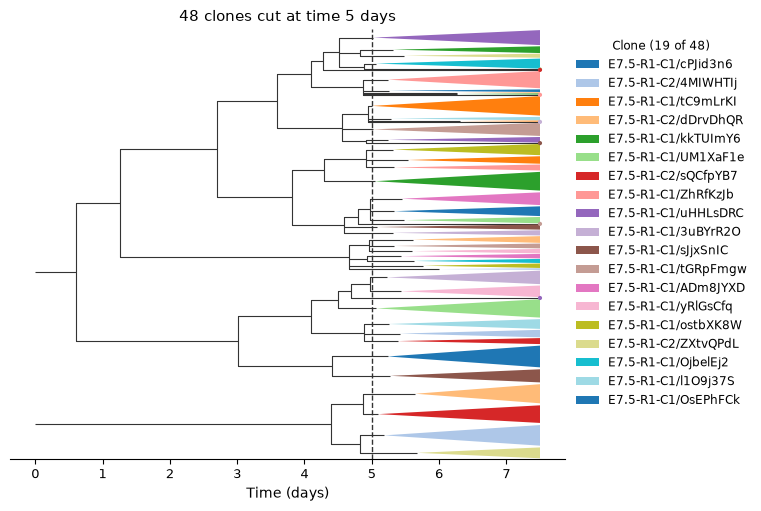

Started: 2026-11-06T09:06:52.566212Z | Wall time: 6.886 s

In [12]:
# Draw the trees, each clone of the cut at E5.0 in its own color.
ds.plots.phylogeny(cuts[5.0])

Each clone of the cut is a wedge in its own color, drawn from its first branching to its cells at day 7.5, and the dashed line marks the cut. The legend names the largest clones by their tree and the name of their root. The first tree's earliest branching falls at about day 0.6 and the second tree's at about day 4.4, although the founder cells were injected at the 8-cell stage, about E2.5. Read the times as estimates, roughest for the earliest branchings: the authors scaled each tree from day 0 at its root, as if marks accumulated at one rate from the root to the leaves.

## Measure coupling at each cut

Cell types that share clones descend from common ancestors, so the clones that two types share at a cut show whether their lineages were still joined at that time. `clones.coupling` measures each pair of cell types by how similarly their cells spread over the clones, CoSpar's default measure [@Wang_2022], and compares it with the couplings of shuffled cell types, as a z-score: its distance from their mean in their standard deviations. Measure the eight cell types of 10 or more donor cells; the three primordial germ cells and the one prechordal plate cell are too few to measure.

In [13]:
# Keep the cell types of at least 10 donor cells.
type_sizes = cell_types[cell_types != "host"].value_counts()
measured_types = type_sizes.index[type_sizes >= 10]
ds.cells.insert("measured_type", cell_types.isin(measured_types), overwrite=True)
measured_cells = ds.snapshot_cell_selection("measured_type")

# Measure the coupling of every pair of these cell types at each cut.
couplings = {
    time: ds.clones.coupling(
        clones, group_by="cell_type", cell_selection=measured_cells
    )
    for time, clones in cuts.items()
}

# Collect each pair's z-score at each cut, and list the five pairs whose
# z-score is highest at any cut.
z_scores = pd.DataFrame(
    {
        f"E{time}": coupling.pairs.set_index(["group_1", "group_2"])["z_score"]
        for time, coupling in couplings.items()
    }
)
z_scores.loc[z_scores.max(axis=1).nlargest(5).index].round(1)

E5.0  E5.5  E6.0  E6.5  \
group_1                 group_2                                                
Extraembryonic mesoderm Hematoendothelial progenitor   0.0   1.0   3.3   3.9   
Epiblast                Primitive streak               1.6   1.1   2.7   3.6   
                        Rostral ectoderm               0.1   0.5   1.7   1.2   
Definitive endoderm     Notochord                     -1.2  -0.3   1.0  -0.4   
Nascent mesoderm        Primitive streak              -1.0  -0.3  -0.2  -1.0   

                                                      E7.0  
group_1                 group_2                             
Extraembryonic mesoderm Hematoendothelial progenitor   2.2  
Epiblast                Primitive streak               1.5  
                        Rostral ectoderm               1.0  
Definitive endoderm     Notochord                     -0.3  
Nascent mesoderm        Primitive streak               0.8

Started: 2026-11-06T09:06:59.454229Z | Wall time: 3.068 s

At E5.0, no pair stands more than 1.6 standard deviations above chance: no two cell types share the clones of E5.0 more than shuffled labels do. From E6.0, two pairs share clones far more than chance, 2.7 to 3.9 standard deviations above it: the extraembryonic mesoderm with the hematoendothelial progenitors, and the epiblast with the primitive streak. The epiblast with the rostral ectoderm follows, 1.2 to 1.7 above. By E7.0 the z-scores shrink, as 78 clones of two or more cells remain to link the types. Draw every pair at E6.5.

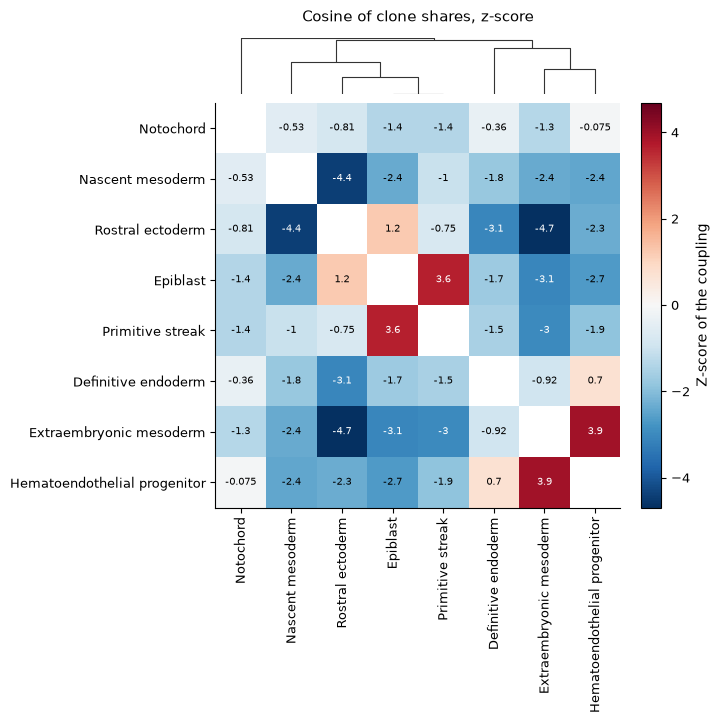

Started: 2026-11-06T09:07:02.524186Z | Wall time: 0.346 s

In [14]:
# Draw the z-scores of every pair at E6.5, with the cell types ordered by
# average linkage on their coupling.
ds.plots.clone_coupling(couplings[6.5])

The extraembryonic mesoderm gives the yolk sac's first blood and vessels, and at E6.5 its lineages are shared with the hematoendothelial progenitors and with no other cell type above chance. The epiblast shares lineages with the primitive streak, which forms in the posterior epiblast, and with the rostral ectoderm, while the primitive streak and the rostral ectoderm share fewer than chance. The most negative z-scores, of the rostral ectoderm with the extraembryonic mesoderm, -4.7, and with the nascent mesoderm, -4.4, show that by E6.5 the lineages of the ectoderm and of the mesoderm had parted. Shuffled labels spread each clone over every cell type, so once lineages narrow to a few fates most pairs fall below their null: read the order of the z-scores more than their sign.

@Colgan_2026 followed fate restriction across their embryos: ancestral cells gave all three germ layers until a weak bias appeared at about E4.0, the bias grew during gastrulation, from about E6.5 to E7.5, the extraembryonic mesoderm was among the earliest restricted cell types, and the endoderm restricted earliest of the germ layers, around E7.0. This embryo follows the same course: no pair of cell types stands out at E5.0, and the extraembryonic mesoderm couples with its blood and vessel progenitors from E6.0. The embryo holds too few cells to time the endoderm's restriction: 39 donor cells of the definitive endoderm, and 17 of the notochord, which the paper links to the endoderm. The two couple 1.0 standard deviation above chance at E6.0 and below chance at the other cuts.